# ۰۱ · کشف داده — exploration

این نوتبوک **تولیدشده** است: سلول‌هایش همین حالا روی همین دیتابیس اجرا شده‌اند و
خروجی‌ها چیزی‌اند که برگشتند، نه چیزی که کسی نوشت. سازندهٔ فایل:
`scripts/build_exploration_notebook.py` (بند ۹.۱ چک‌لیست).

سلسله‌مراتب عمدي است: هر سلول از `capstone.*` صدا می‌زند، چون یک نوتبوکی که
خطِ تولید ویژگی را از نو بنویسد، دومین منبع حقیقت است و اولین جایی که دو منبع
با هم نمی‌خوانند، همان‌جاست که یک ادعای درزِ اطلاعاتی متولد می‌شود.

هیچ عددی اینجا اختراع نمی‌شود. اگر جدولی خالی است، یعنی اندازه گرفته نشده.

<!--section:intent-->

<!--section:intent-->

## ۱ · زمینه و اتصال

دیتابیس از `CAPSTONE_DATABASE_URI` می‌آید و از هیچ مقدار پیش‌فرضی در فایل config نمی‌آید (بند ۱۰.۲).

<!--section:context-->

<!--section:context-->

In [1]:
import os
from collections import Counter
from capstone.config import load_contract
from capstone.features import connect, database_uri
from capstone import model
from pathlib import Path

import capstone
from capstone.cli import default_config_path

# the stage folder from the package itself, not from the working directory (review B22), and the
# decided config the chain runs with, not the undecided example
STAGE = Path(capstone.__file__).resolve().parents[2]
config = load_contract(default_config_path(STAGE))
SEED = config.model.random_seed  # one seed, defined once; nothing below draws at random
uri = database_uri(config, purpose="the exploration notebook")
engine = connect(uri)
print('engine:', uri.split('://')[0])
print('label:', model.label_definition())

engine: postgresql
label: a review is negative at a score of 1..2


## ۲ · برچسب، همان‌طور که تعریف شده

سه عددِ لازم قبل از هر مدل‌سازی: چند سفارش برچسب‌دار است، چند تا بی‌برچسب، و چند تا منفی. تفکیکِ «بی‌برچسب» از «مثبت» همان چیزی است که D2 در `decisions.md` برای آن جنگیده شد؛ یک نوتبوک که آن را با صفر پر کند، همان اشتباه را در قالب روایت تکرار می‌کند.

<!--section:label-->

<!--section:label-->

In [2]:
frame = model.read_frame(config, external='auto')
total = len(frame.rows)
labelled = [row for row in frame.rows if row[model.LABEL_KEY] is not None]
negatives = [row for row in labelled if row[model.LABEL_KEY]]
print(f'rows in frame: {total}')
print(f'labelled: {len(labelled)}   unlabelled: {total - len(labelled)}')
print(f'negatives: {len(negatives)}   rate: {len(negatives) / max(len(labelled), 1):.4f}')
print(f'feature columns: {len(frame.columns)}')

rows in frame: 99281
labelled: 98518   unlabelled: 763
negatives: 14454   rate: 0.1467
feature columns: 33


In [3]:
worst = Counter(row['worst_score'] for row in labelled)
print('worst_score histogram (the label is a MIN over reviews, so this is its raw shape):')
for score in sorted(key for key in worst if key is not None):
    print(f'  {score}: {worst[score]}')
counts = Counter(row['review_count'] for row in labelled if row['review_count'] is not None)
multi = sum(value for key, value in counts.items() if key and key > 1)
print(f'orders with more than one review: {multi}  (D3: worst_score_wins)')

worst_score histogram (the label is a MIN over reviews, so this is its raw shape):
  1: 11330
  2: 3124
  3: 8120
  4: 19031
  5: 56913
orders with more than one review: 546  (D3: worst_score_wins)


## ۳ · توزیع ویژگی‌ها و «گم‌شده‌ها»

§۷ `decisions.md` صفر‌کردن را ممنوع کرده، پس ستونِ دارای NULL باید در همین نوتبوک دیده شود، نه در یک متدِ بی‌صدا. شمارشِ NULLها تنها چیزی است که بعداً در فاز ۸ (drift) مقایسه می‌شود، پس اینجا هم همین تابع می‌خواند.

<!--section:missing-->

<!--section:missing-->

In [4]:
missing: Counter = Counter()
for row in frame.rows:
    for name in frame.columns:
        if row.get(name) is None:
            missing[name] += 1
print('columns with at least one NULL, worst first:')
for name, count in missing.most_common():
    print(f'  {name:<34} {count:>7} of {total}  ({count / max(total, 1):.2%})')
if not missing:
    print('  none -- every feature cell in this frame is non-NULL')

columns with at least one NULL, worst first:
  days_since_prior_order               96074 of 99281  (96.77%)
  product_category_name_english         2068 of 99281  (2.08%)
  product_photos_qty                    2046 of 99281  (2.06%)
  customer_seller_span_sq               1119 of 99281  (1.13%)
  external_ibge_code                     734 of 99281  (0.74%)
  external_indicator_count               734 of 99281  (0.74%)
  external_density_2010                  734 of 99281  (0.74%)
  product_weight_g                       645 of 99281  (0.65%)
  price_sum                              629 of 99281  (0.63%)
  price_spread                           629 of 99281  (0.63%)
  freight_share                          629 of 99281  (0.63%)
  shipping_limit_days                    629 of 99281  (0.63%)
  seller_state                           629 of 99281  (0.63%)
  payment_sum                              1 of 99281  (0.00%)
  installments_max                         1 of 99281  (0.00%)
  payment

## ۴ · ممیزی زمانی

سوالِ بند ۹.۱ چک‌لیست این است: آیا هر ستونی که وارد مدل می‌شود در لحظهٔ `order_approved_at` وجود داشته؟ پاسخ در خودِ داده نیست، در `capstone.column_audit` و گاردهای `sql/002` است؛ نوتبوک فقط گزارش می‌دهد گارد چه می‌گوید.
این سلول عمداً یک `SELECT` نوشتگی نیست: از همان `audit` می‌خواند که CLI هم می‌خواند، تا نوتبوک و `capstone audit` هیچ‌وقت دو جواب نداشته باشند.

<!--section:time-audit-->

<!--section:time-audit-->

In [5]:
from capstone import audit

# the same reader the CLI uses -- one source, so the notebook and `capstone audit`
# cannot end up disagreeing about what was verified
verdicts = audit.load_audit(STAGE / 'docs' / 'evidence' / 'column_audit.csv')
summary = audit.summarise(verdicts)
print('column audit, as the CLI reads it:')
for key, value in summary.items():
    print(f'  {key:<12} {value}')
problems = audit.audit_problems(verdicts)
print(f'problems: {len(problems)}')
for line in problems[:10]:
    print('  -', line)
if not problems:
    print('  none, so require_allowed can vouch for every frame column')

column audit, as the CLI reads it:
  rows         53
  tables       9
  allowed      43
  forbidden    10
  unverified   0
  usable       43
  problems     0
problems: 0
  none, so require_allowed can vouch for every frame column


## ۵ · سیگنال بیرونی (IBGE، چگالی جمعیت سرشماری ۲۰۱۰، متغیر ۶۱۶)

ستون‌های `external_*` از `sql/005_external_signal.sql` می‌آیند. پوشششان یک عددِ تحویلی است: «سیگنال به چند درصد سفارش‌ها رسید» بدون آن، جملهٔ «کمک کرد» بی‌معناست.

<!--section:external-->

<!--section:external-->

In [6]:
external = frame.external_columns()
print(f'external columns in the frame: {external or "none"}')
if external:
    matched = sum(1 for row in frame.rows if row.get('external_matched'))
    print(f'rows with external_matched: {matched} of {total} ({matched / max(total, 1):.2%})')
    for name in external:
        filled = sum(1 for row in frame.rows if row.get(name) is not None)
        print(f'  {name}: {filled} non-null')
else:
    print('the signal has not been joined into this frame yet -- run sql/005 and re-run')

external columns in the frame: ('external_matched', 'external_ibge_code', 'external_indicator_count', 'external_density_2010')
rows with external_matched: 98547 of 99281 (99.26%)
  external_matched: 99281 non-null
  external_ibge_code: 98547 non-null
  external_indicator_count: 98547 non-null
  external_density_2010: 98547 non-null


## ۶ · نمودارها: برچسب در طول زمان و چند ویژگیِ کلیدی

سه نمودار، همه روی سفارش‌های برچسب‌دار: نرخ نظر منفی در هر ماهِ تأیید (خط قرمز = مرز تقسیم)، و توزیعِ دو ویژگی که فرضیهٔ اصلی پشتشان است (مدتِ وعدهٔ تحویل و سهم کرایه) جدا برای منفی و غیرمنفی. جدولِ داده از همان `capstone.system.read_frame` می‌آید که لایهٔ مدل می‌خواند.

<!--section:plots-->

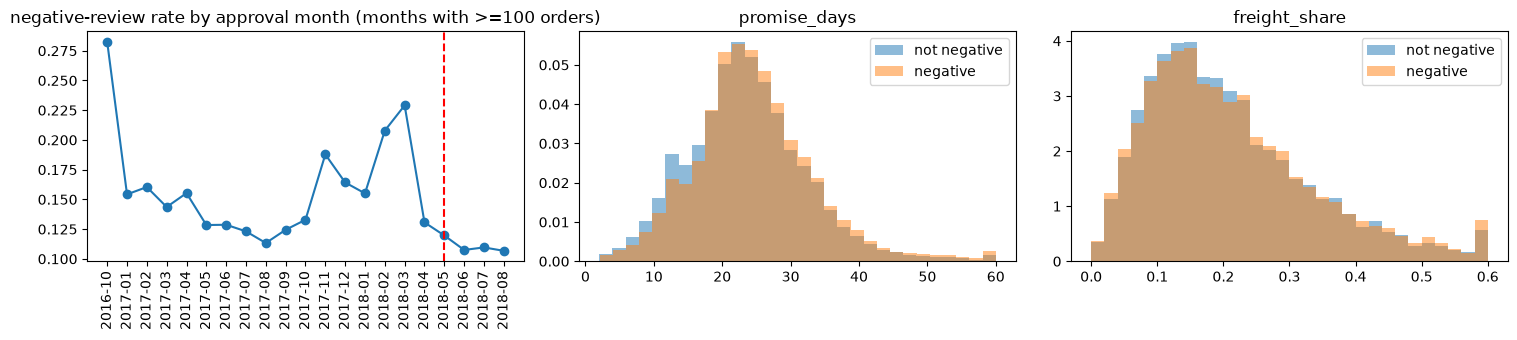

                  mean  size
decision_month              
2016-10         0.2825   315
2017-01         0.1543   752
2017-02         0.1604  1752
2017-03         0.1436  2667
2017-04         0.1553  2357
2017-05         0.1285  3659
2017-06         0.1287  3225
2017-07         0.1231  3939
2017-08         0.1133  4315
2017-09         0.1244  4267
2017-10         0.1329  4553
2017-11         0.1878  7331
2017-12         0.1642  5772
2018-01         0.1551  7119
2018-02         0.2078  6650
2018-03         0.2291  7225
2018-04         0.1307  6726
2018-05         0.1197  7028
2018-06         0.1075  6139
2018-07         0.1096  6130
2018-08         0.1068  6594


In [7]:
import matplotlib.pyplot as plt
import pandas as pd
from capstone import system

df = system.read_frame(engine)
lab = df[df['is_negative'].notna()]
rate = lab.groupby('decision_month')['is_negative'].agg(['mean', 'size'])
rate = rate[rate['size'] >= 100]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].plot(rate.index, rate['mean'], marker='o')
axes[0].axvline(str(config.split.boundary)[:7], color='red', ls='--')
axes[0].set_title('negative-review rate by approval month (months with >=100 orders)')
axes[0].tick_params(axis='x', rotation=90)
for ax, column, clip in ((axes[1], 'promise_days', 60), (axes[2], 'freight_share', 0.6)):
    for flag, name in ((0.0, 'not negative'), (1.0, 'negative')):
        values = lab.loc[lab['is_negative'] == flag, column].dropna().clip(upper=clip)
        ax.hist(values, bins=30, density=True, alpha=0.5, label=name)
    ax.set_title(column); ax.legend()
plt.tight_layout()
plt.show()
print(rate.round(4).to_string())

## ۷ · آزمون فرضیه‌ها (فقط روی پنجرهٔ آموزش)

برای هر ویژگیِ عددی یک آزمون Mann-Whitney (منفی در برابر غیرمنفی) و اندازهٔ اثر به‌صورت AUC تک‌ستونی (۰٫۵ = بی‌اثر)؛ برای ستون‌های متنی آزمون کای‌دو روی جدول توافقی. همه روی سفارش‌های **تا مرز** (`split.boundary`) تا ماه‌های ارزیابی دیده نشوند. فرضیه‌ای که p-value بزرگ یا اثرِ نزدیک ۰٫۵ دارد «رد شده» علامت می‌خورد و در گزارش هم همین‌طور می‌آید.

<!--section:hypotheses-->

In [8]:
from scipy.stats import mannwhitneyu, chi2_contingency

split = system.time_split(df, config.split.boundary, config.model.validation_months)  # the model's own split
train = df[split.train & df['is_negative'].notna()]
numeric, categorical = system.feature_columns(df, external=False)
if system.EXTERNAL_COLUMN in df.columns:
    numeric = numeric + [system.EXTERNAL_COLUMN]
rows = []
for column in numeric:
    neg = train.loc[train['is_negative'] == 1, column].dropna()
    pos = train.loc[train['is_negative'] == 0, column].dropna()
    if neg.nunique() < 2 and pos.nunique() < 2:
        continue
    stat, p = mannwhitneyu(neg, pos, alternative='two-sided')
    rows.append({'feature': column, 'test': 'Mann-Whitney', 'effect_auc': stat / (len(neg) * len(pos)), 'p_value': p})
for column in categorical:
    table = pd.crosstab(train[column].fillna('(blank)'), train['is_negative'])
    table = table[table.sum(axis=1) >= 50]
    chi2, p, dof, _ = chi2_contingency(table)
    rows.append({'feature': column, 'test': f'chi2 dof={dof}', 'effect_auc': None, 'p_value': p})
tests = pd.DataFrame(rows)
tests['verdict'] = [
    'supported' if p < 0.001 and (auc is None or pd.isna(auc) or abs(auc - 0.5) >= 0.02) else 'not supported'
    for p, auc in zip(tests['p_value'], tests['effect_auc'])
]
tests['strength'] = (tests['effect_auc'] - 0.5).abs()
print(f'training window: {len(train)} labelled orders, {int(train["is_negative"].sum())} negatives')
print(tests.sort_values(['verdict', 'strength'], ascending=[False, False]).drop(columns='strength').round(5).to_string(index=False))

training window: 79654 labelled orders, 12417 negatives
                      feature         test  effect_auc  p_value       verdict
                  freight_sum Mann-Whitney     0.56130  0.00000     supported
       days_since_prior_order Mann-Whitney     0.44523  0.00064     supported
                  payment_sum Mann-Whitney     0.55216  0.00000     supported
                    price_sum Mann-Whitney     0.54441  0.00000     supported
      customer_seller_span_sq Mann-Whitney     0.54193  0.00000     supported
                      n_items Mann-Whitney     0.53213  0.00000     supported
                 promise_days Mann-Whitney     0.53192  0.00000     supported
             installments_max Mann-Whitney     0.52366  0.00000     supported
                 price_spread Mann-Whitney     0.52202  0.00000     supported
         category_unavailable Mann-Whitney     0.52188  0.00000     supported
          customer_zip_region Mann-Whitney     0.52043  0.00000     supported
        

## ۸ · فرضیه‌ها و شکست‌ها

چیزی که این نوتبوک باید نشان دهد فقط توزیع‌ها نیستند؛ فرضیه‌هایی که مردند هم بخشی از تحویل‌اند (بند ۹.۱: «کشف، EDA، ممیزی زمانی، فرضیه‌ها، شکست‌ها»). سلول آخر عمداً یک چیزِ محاسبه‌شدهٔ بی‌ادعا می‌نویسد تا ادعای بزرگ، عددِ کوچکِ خودش را داشته باشد.

مسیرهایی که امتحان شدند و کنار رفتند (شرح کامل در `report.md` بخش ۷ و `decisions.md`):

- **چگالی جمعیت به‌عنوان سیگنال بیرونی:** در جدول بالا اثرش نزدیک ۰٫۵ است و «not supported» خورده؛ در مدل هم بازهٔ اطمینانِ اثرش صفر را در بر دارد (`docs/evidence/model-ablation-run.txt`). فرضیه رد شد و مدل تحویلی بدون آن است.
- **سرشماری ۲۰۲۲** اول به‌جای ۲۰۱۰ آمده بود: عددی که در لحظهٔ تأیید سفارش‌های ۲۰۱۶–۲۰۱۸ وجود نداشت، یعنی نشت از راه منبع بیرونی.
- **فرضیهٔ «درآمد»** برای منبع بیرونی: جدول IBGE اصلاً متغیر درآمد نداشت.
- **چند فرضیهٔ ویژگی** (مثلاً `shipping_limit_days`، `n_products`، `product_weight_g`) روی آموزش اثری نزدیک به صفر دارند؛ در مدل مانده‌اند چون مدل درختی خودش وزنشان را کم می‌کند، ولی در گزارش «حمایت‌نشده» خوانده می‌شوند.

سلول آخر نرخ منفی هر ماه را می‌دهد؛ ماه‌هایی با کمتر از ۱۰۰ سفارش برچسب‌دار در دامنه حساب نمی‌شوند (۲۰۱۶-۰۹، ۲۰۱۶-۱۲ و ۲۰۱۸-۰۹ یک سفارش دارند).

<!--section:failures-->

<!--section:failures-->

In [9]:
# per-month negative rate, which is the distribution phase 8 compares train against
# eval. No model is fitted here on purpose: a drift claim that needs a fitted scorer
# is not a drift claim, and model.month_spread() is the place scores belong.
by_month: dict[str, list[int]] = {}
for row in labelled:
    month = row.get(model.MONTH_KEY) or 'unknown'
    hit = by_month.setdefault(month, [0, 0])
    hit[0] += 1
    hit[1] += 1 if row[model.LABEL_KEY] else 0
print(f'months with labelled rows: {len(by_month)}')
for month in sorted(by_month):
    rows, negative = by_month[month]
    print(f'  {month}  rows {rows:>6}  negatives {negative:>6}  rate {negative / max(rows, 1):.4f}')
rates = [negative / rows for rows, negative in by_month.values() if rows >= 100]
if rates:
    print(f'spread across months with >= 100 labelled orders: {min(rates):.4f} .. {max(rates):.4f}  '
          f'(a range of {max(rates) - min(rates):.4f})')
    print('a wide range is the hypothesis that the feature window drifts; the report')
    print('section that quotes it has to carry the number, not this cell.')

engine.close()

months with labelled rows: 24
  2016-09  rows      1  negatives      1  rate 1.0000
  2016-10  rows    315  negatives     89  rate 0.2825
  2016-12  rows      1  negatives      0  rate 0.0000
  2017-01  rows    752  negatives    116  rate 0.1543
  2017-02  rows   1752  negatives    281  rate 0.1604
  2017-03  rows   2667  negatives    383  rate 0.1436
  2017-04  rows   2357  negatives    366  rate 0.1553
  2017-05  rows   3659  negatives    470  rate 0.1285
  2017-06  rows   3225  negatives    415  rate 0.1287
  2017-07  rows   3939  negatives    485  rate 0.1231
  2017-08  rows   4315  negatives    489  rate 0.1133
  2017-09  rows   4267  negatives    531  rate 0.1244
  2017-10  rows   4553  negatives    605  rate 0.1329
  2017-11  rows   7331  negatives   1377  rate 0.1878
  2017-12  rows   5772  negatives    948  rate 0.1642
  2018-01  rows   7119  negatives   1104  rate 0.1551
  2018-02  rows   6650  negatives   1382  rate 0.2078
  2018-03  rows   7225  negatives   1655  rate 0.229